# B2 · Cleaning and alignment

Turns the raw 2024 car data into samples that know **which lap** they belong to, **how far into the lap** they
are, and **whether that lap can be trusted**. Nothing is dropped: every reason to distrust a lap is a boolean
column, and `clean` is only the default combination.

The code lives in `pipeline/fw47_core/clean.py` so the replayer (A2) and later notebooks use the same logic.
`analysis/build_clean.py` runs it over every session and writes `data/clean/{laps,samples}/`:

```bash
.venv/bin/python analysis/build_clean.py --seasons 2024
```

Only 2024 has car data so far (B1), so this notebook covers 2024.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..') / 'pipeline'))  # until A1 makes fw47_core pip-installable
from fw47_core.clean import LAP_FLAGS, LENGTH_TOL, LAP_GAP_S, DRS_OPEN

CLEAN = Path('..') / 'data' / 'clean'
RAW = Path('..') / 'data' / 'parquet'
SEASON = 2024
pd.set_option('display.max_columns', 30)

sessions = pd.read_parquet(RAW / 'sessions' / f'season={SEASON}' / 'sessions.parquet').set_index('session_key')
track = sessions['circuit_short_name']

def load(kind, key, columns=None):
    return pd.read_parquet(CLEAN / kind / f'season={SEASON}' / f'{key}.parquet', columns=columns)

keys = sorted(int(f.stem) for f in (CLEAN / 'laps' / f'season={SEASON}').glob('*.parquet'))
laps = pd.concat([load('laps', k) for k in keys], ignore_index=True)
laps['track'] = laps['session_key'].map(track)
print(len(keys), 'races,', len(laps), 'driver laps')

24 races, 26615 driver laps


## 1. Lap number and lap distance

Each sample is matched to the lap whose `date_start` is the latest one before it, and kept only if it falls
before that lap's end (start + duration; for a lap without a duration, the next lap's start or the car's last
sample, so retirement laps survive for B5). Distance into the lap is the time integral of speed (trapezoid rule).

**Check 1: does a lap add up to the track length?** Integrated length per clean lap against the official
circuit length.

In [2]:
OFFICIAL_M = {'Sakhir': 5412, 'Jeddah': 6174, 'Melbourne': 5278, 'Suzuka': 5807, 'Shanghai': 5451, 'Miami': 5412,
              'Imola': 4909, 'Monte Carlo': 3337, 'Montreal': 4361, 'Catalunya': 4657, 'Spielberg': 4318,
              'Silverstone': 5891, 'Hungaroring': 4381, 'Spa-Francorchamps': 7004, 'Zandvoort': 4259,
              'Monza': 5793, 'Baku': 6003, 'Singapore': 4940, 'Austin': 5513, 'Mexico City': 4304,
              'Interlagos': 4309, 'Las Vegas': 6201, 'Lusail': 5419, 'Yas Marina Circuit': 5281}

c = laps[laps['clean']]
length = c.groupby('track')['integrated_length_m'].agg(clean_laps='size', median='median', sd='std')
length['official'] = length.index.map(OFFICIAL_M)
length['diff %'] = (length['median'] / length['official'] - 1) * 100
length['sd %'] = length['sd'] / length['median'] * 100
length.round(1).sort_values('diff %')

,clean_laps,median,sd,official,diff %,sd %
track,,,,,,
Monte Carlo,1168,3281.1,5.1,3337,-1.7,0.2
Mexico City,1053,4238.2,6.9,4304,-1.5,0.2
Austin,854,5435.9,10.5,5513,-1.4,0.2
Miami,916,5333.6,8.9,5412,-1.4,0.2
Singapore,1099,4872.7,10.9,4940,-1.4,0.2
Jeddah,785,6096.3,9.9,6174,-1.3,0.2
Silverstone,452,5814.6,8.7,5891,-1.3,0.1
Yas Marina Circuit,860,5215.0,8.1,5281,-1.3,0.2
Baku,854,5932.7,11.2,6003,-1.2,0.2


In [3]:
print(f"median difference from official: {length['diff %'].median():.2f}%  "
      f"(range {length['diff %'].min():.1f}% to {length['diff %'].max():.1f}%)")
print(f"median lap-to-lap sd: {length['sd'].median():.1f} m ({length['sd %'].median():.2f}%)")

median difference from official: -1.10%  (range -1.7% to -0.6%)
median lap-to-lap sd: 8.9 m (0.17%)


Every track measures about **1% short** of its official length, very consistently. Official lengths follow the
track centreline; cars take a shorter racing line, and wheel-speed-based speed can read slightly low. Lap-to-lap
spread is about 10 m, so distance is precise even if not exactly "official".

To remove the remaining per-lap drift, `lap_distance_norm_m` rescales each lap to the session's median clean-lap
length. B4 bins on that.

**Check 2: does the same distance land on the same spot on track?** If distance is right, the X/Y position at,
say, 1,500 m should be the same on every lap. For each 25 m bin we measure how far samples sit from that bin's
median position. (OpenF1 X/Y is in decimetres: the X/Y path of a lap is ~9.9× its length in metres.)

In [4]:
KEY = int(sessions.index[track.eq('Sakhir')][0])
s = load('samples', KEY)
cs = s[s['clean'] & s['x'].notna()].copy()

def spread(df, col, bin_m=25):
    b = (df[col] // bin_m).astype(int)
    med = df.groupby(b)[['x', 'y']].transform('median')
    return np.hypot(df['x'] - med['x'], df['y'] - med['y']) / 10   # decimetres -> m

xy = pd.DataFrame({name: spread(cs, col).describe(percentiles=[.5, .9, .99])
                   for name, col in [('raw integration', 'lap_distance_m'), ('normalised', 'lap_distance_norm_m')]}).T
xy[['50%', '90%', '99%']].round(1).rename(columns=lambda c: c + ' (m)')

,50% (m),90% (m),99% (m)
raw integration,8.1,19.5,32.0
normalised,7.3,17.2,27.6


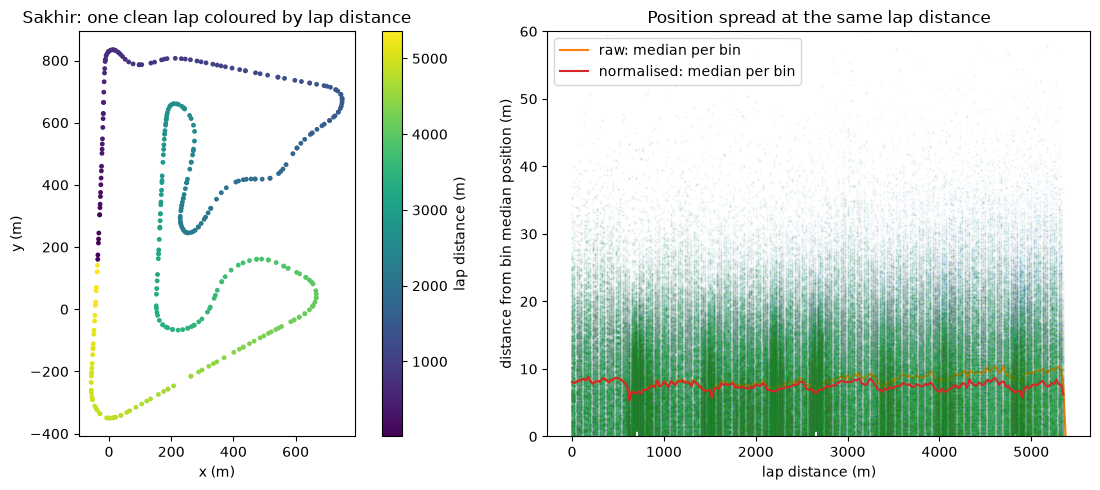

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
one = cs[(cs.driver_number == cs.driver_number.iloc[0])]
one = one[one.lap_number == one.lap_number.iloc[len(one) // 2]]
sc = axes[0].scatter(one.x / 10, one.y / 10, c=one.lap_distance_norm_m, s=6, cmap='viridis')
plt.colorbar(sc, ax=axes[0], label='lap distance (m)')
axes[0].set(title=f'{track[KEY]}: one clean lap coloured by lap distance', aspect='equal', xlabel='x (m)', ylabel='y (m)')
for name, col in [('raw', 'lap_distance_m'), ('normalised', 'lap_distance_norm_m')]:
    e = spread(cs, col)
    axes[1].plot(cs[col] // 25 * 25, e, '.', ms=1, alpha=.05)
    axes[1].plot(*zip(*sorted(e.groupby(cs[col] // 25 * 25).median().items())), label=f'{name}: median per bin')
axes[1].set(ylim=(0, 60), xlabel='lap distance (m)', ylabel='distance from bin median position (m)',
            title='Position spread at the same lap distance')
axes[1].legend(); plt.tight_layout()

## 2. Lap flags

One boolean column per reason to distrust a lap. How each is derived:

| Flag | Rule |
|---|---|
| `standing_start` | lap 1, or any lap where the car is below 30 km/h in its first 400 m: catches red-flag restarts, which OpenF1 numbers inconsistently (at Suzuka, "lap 1" is the restart's formation lap and lap 3 the real start) |
| `pit_in` | the lap before a pit-out lap: it ends in the pit lane. (OpenF1's `pit.date` falls inside the *out*-lap, after the car crosses the timing line in the pit lane.) |
| `pit_out` | OpenF1 `is_pit_out_lap` |
| `safety_car` | lap overlaps "SAFETY CAR DEPLOYED" → next "TRACK CLEAR" |
| `vsc` | lap overlaps "VIRTUAL SAFETY CAR DEPLOYED" → "… ENDING" + 15 s |
| `red_flag` | lap overlaps "RED FLAG" → next "SESSION STARTED" |
| `yellow` | lap overlaps a (double) yellow in any sector, until that sector or the track is cleared (max 5 min) |
| `deleted` | race control deleted the lap time ("CAR 16 (LEC) TIME … DELETED … LAP 12") |
| `wet_tyres` | the car was on intermediates or wets (stints) |
| `rain` | a weather reading with rainfall within ±1 min of the lap |
| `missing_duration` | OpenF1 has no lap time (often the lap a car retired on) |
| `has_gap` | a gap of more than 2 s between samples inside the lap |
| `bad_length` | integrated lap length more than 2% from the session median: broken lap boundaries in the source |

Share of driver laps carrying each flag, per race (a lap can carry several):

In [6]:
rates = laps.groupby('track', sort=False)[LAP_FLAGS + ['clean']].mean().mul(100).round(0).astype(int)
rates.loc['ALL 2024'] = laps[LAP_FLAGS + ['clean']].mean().mul(100).round(1)
rates

,standing_start,pit_in,pit_out,safety_car,vsc,red_flag,yellow,deleted,wet_tyres,rain,missing_duration,has_gap,bad_length,clean
track,,,,,,,,,,,,,,
Sakhir,2.0,4.0,4.0,0.0,0.0,0.0,4.0,2.0,0.0,0.0,0.0,0.0,1.0,88.0
Jeddah,2.0,2.0,2.0,6.0,0.0,0.0,7.0,2.0,0.0,0.0,0.0,0.0,2.0,87.0
Melbourne,2.0,4.0,4.0,0.0,5.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,1.0,85.0
Suzuka,4.0,4.0,6.0,0.0,0.0,2.0,2.0,1.0,0.0,0.0,0.0,0.0,5.0,83.0
Miami,2.0,3.0,3.0,9.0,3.0,0.0,7.0,2.0,0.0,0.0,0.0,0.0,0.0,82.0
Imola,2.0,2.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,93.0
Monte Carlo,2.0,2.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,2.0,94.0
Montreal,2.0,3.0,5.0,15.0,0.0,0.0,23.0,3.0,65.0,30.0,0.0,0.0,2.0,20.0
Catalunya,1.0,3.0,3.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0,0.0,0.0,0.0,87.0


In [7]:
# Flags that are the *only* reason a lap is excluded: what each choice costs on its own
only = {f: (laps[f] & (laps[LAP_FLAGS].sum(axis=1) == 1)).sum() for f in LAP_FLAGS}
pd.DataFrame({'laps flagged': laps[LAP_FLAGS].sum(), 'only reason': pd.Series(only)}).sort_values('laps flagged', ascending=False)

,laps flagged,only reason
wet_tyres,2195,355
rain,1777,264
yellow,1602,412
bad_length,1443,1
safety_car,1012,191
pit_out,845,587
pit_in,807,548
standing_start,503,222
deleted,328,228
vsc,242,57


**Wet races are their own regime.** Montreal (21% clean), Silverstone (47%) and Interlagos (0%: the whole race
was on intermediates) lose most of their laps. That is correct for a dry-weather baseline. Wet running would need
its own baselines, and is out of scope for v1.

**Lusail and Shanghai** lose a lot to safety cars. **Austin** loses 13% to yellow flags.

## 3. What each excluded category looks like

Speed against lap distance for one example lap per flag (red), over the band of that race's clean laps
(grey: 10th–90th percentile, black: median). This is why each category is kept out of the baseline.

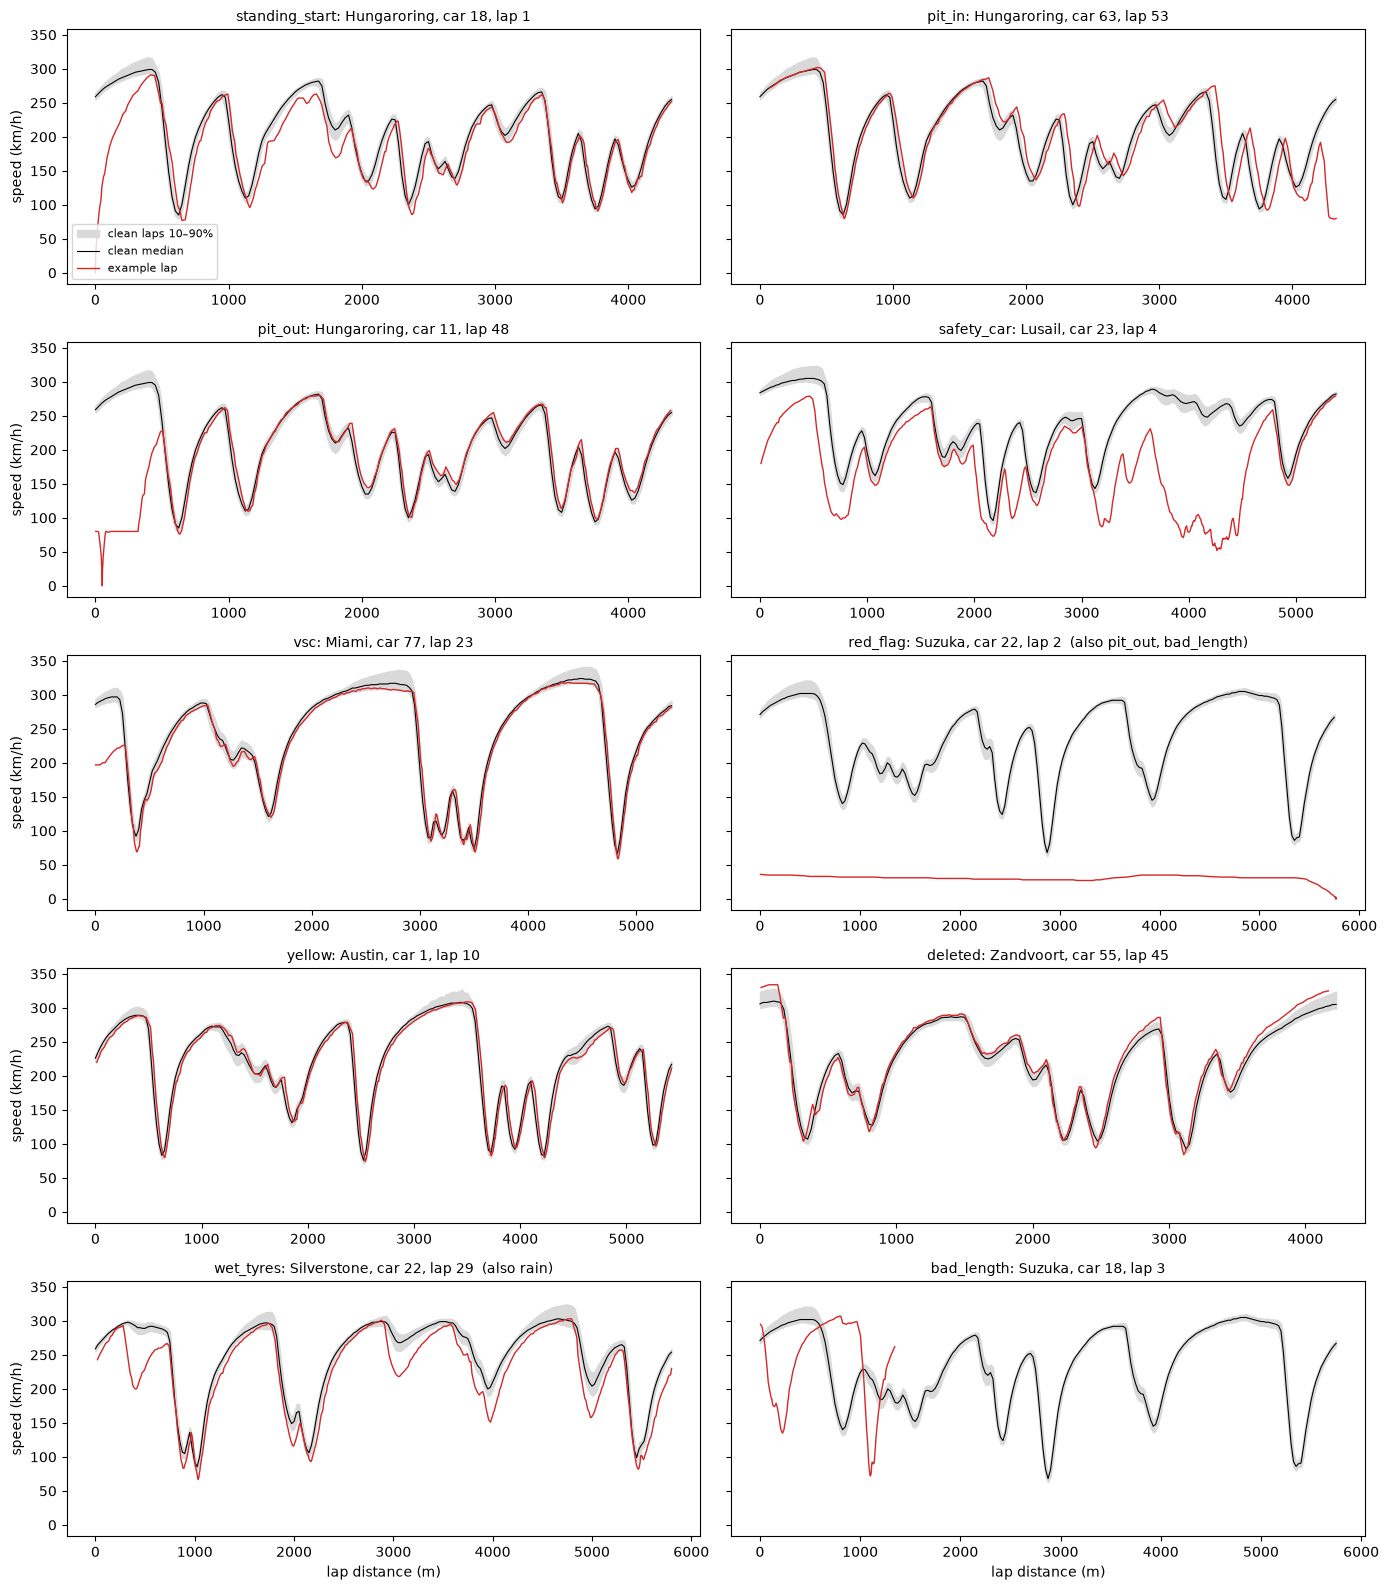

In [8]:
def band(s, bin_m=25):
    c = s[s['clean']]
    b = (c['lap_distance_norm_m'] // bin_m) * bin_m
    return c.groupby(b)['speed'].quantile([.1, .5, .9]).unstack()

def example(flag):
    """First dry-race lap where `flag` is the only flag (or, failing that, any lap with it)."""
    has_band = laps.groupby('session_key')['clean'].transform('mean') > .2   # need clean laps to draw the band
    dry = laps[has_band & (~laps[['wet_tyres', 'rain']].any(axis=1) | (flag in ('wet_tyres', 'rain')))]
    solo = dry[dry[flag] & (dry[LAP_FLAGS].sum(axis=1) == 1)]
    pick = solo if len(solo) else dry[dry[flag]]
    return pick.iloc[len(pick) // 2] if len(pick) else None

show = ['standing_start', 'pit_in', 'pit_out', 'safety_car', 'vsc', 'red_flag', 'yellow', 'deleted', 'wet_tyres', 'bad_length']
fig, axes = plt.subplots(5, 2, figsize=(14, 16), sharey=True)
cache = {}
for ax, flag in zip(axes.flat, show):
    lap = example(flag)
    if lap is None:
        ax.set_title(f'{flag}: no example'); continue
    k = int(lap.session_key)
    if k not in cache:
        cache = {k: load('samples', k, ['driver_number', 'lap_number', 'lap_distance_norm_m', 'speed', 'clean'])}
    s_ = cache[k]
    q = band(s_)
    ax.fill_between(q.index, q[.1], q[.9], color='0.85', label='clean laps 10–90%')
    ax.plot(q.index, q[.5], color='k', lw=.8, label='clean median')
    l = s_[(s_.driver_number == lap.driver_number) & (s_.lap_number == lap.lap_number)]
    ax.plot(l.lap_distance_norm_m, l.speed, color='tab:red', lw=1, label='example lap')
    other = [f for f in LAP_FLAGS if lap[f] and f != flag]
    ax.set_title(f'{flag}: {track[k]}, car {int(lap.driver_number)}, lap {int(lap.lap_number)}'
                 + (f"  (also {', '.join(other)})" if other else ''), fontsize=10)
axes[0, 0].legend(fontsize=8, loc='lower left')
for ax in axes[-1]: ax.set_xlabel('lap distance (m)')
for ax in axes[:, 0]: ax.set_ylabel('speed (km/h)')
plt.tight_layout()

## 4. Sample quality checks

On every sample: the gap since the previous sample of the same car, duplicate timestamps, and impossible values.
Out-of-range values are fixed (throttle clipped to 100, brake → on/off, gear > 8 → missing) and the raw reading
flagged `q_bad_value`. `q_brake_stuck` marks brake = 100 at full throttle for ~1 s or more (4+ samples): a stuck brake
channel, found while auditing the rules in B3 (up to 22 s with the car accelerating). Single overlapping samples are
normal as a driver lifts and brakes.

In [9]:
QCOLS = ['session_key', 'in_lap', 'gap_before_s', 'q_gap', 'q_duplicate', 'q_bad_value', 'q_brake_stuck']
q = pd.concat([load('samples', k, QCOLS) for k in keys], ignore_index=True)
qt = q.groupby(q['in_lap'].map({True: 'inside a race lap', False: 'outside (grid, garage, after flag)'})).agg(
    samples=('q_gap', 'size'), gap_over_1s=('q_gap', 'mean'), gap_over_2s=('gap_before_s', lambda g: (g > 2).mean()),
    duplicate=('q_duplicate', 'mean'), bad_value=('q_bad_value', 'mean'), brake_stuck=('q_brake_stuck', 'mean'))
qt.style.format({'samples': '{:,.0f}', **{c: '{:.3%}' for c in qt.columns[1:]}})

,samples,gap_over_1s,gap_over_2s,duplicate,bad_value,brake_stuck
in_lap,,,,,,
inside a race lap,"9,389,738",0.125%,0.001%,0.000%,0.367%,0.025%
"outside (grid, garage, after flag)","7,160,636",0.121%,0.001%,0.000%,20.285%,0.001%


Bad values are almost all **outside** race laps: in the garage the car reports throttle = brake = 104 together,
a sentinel rather than a reading. Inside laps they are rare.

**Why the lap-level gap threshold is 2 s, not 1 s.** Gaps of 1–1.5 s are common (about one per lap) and don't
change the measured lap length:

In [10]:
mg = pd.concat([load('samples', k, ['session_key', 'driver_number', 'lap_number', 'gap_before_s', 'in_lap'])
                .query('in_lap').groupby(['session_key', 'driver_number', 'lap_number'])['gap_before_s'].max()
                for k in keys]).rename('max_gap_s')
g = laps.join(mg, on=['session_key', 'driver_number', 'lap_number'])
g = g[~g[[f for f in LAP_FLAGS if f not in ('has_gap', 'bad_length')]].any(axis=1)]
g['length error (m)'] = (g['integrated_length_m'] - g['track_length_m']).abs()
g.groupby(pd.cut(g['max_gap_s'], [0, .5, 1, 1.5, 2, 5, 60]), observed=True)['length error (m)'].describe(percentiles=[.5, .9])[['count', '50%', '90%', 'max']].round(1)

,count,50%,90%,max
max_gap_s,,,,
"(0.0, 0.5]",3364.0,5.0,13.2,3535.0
"(0.5, 1.0]",10234.0,5.3,14.2,83.5
"(1.0, 1.5]",7194.0,5.4,14.3,90.1
"(1.5, 2.0]",48.0,8.5,24.6,48.4
"(5.0, 60.0]",17.0,29.2,76.7,114.2


## 5. Data funnel

Samples removed by each filter, applied in order: racing context first, then data problems. The order matters for the "removed" column, not for the final
count. The last row is what B3–B6 build baselines and measure alert rates on.

In [11]:
FCOLS = ['in_lap', 'q_bad_value', 'q_duplicate', 'q_brake_stuck'] + LAP_FLAGS + ['clean']
f = pd.concat([load('samples', k, FCOLS) for k in keys], ignore_index=True)
for col in LAP_FLAGS:
    f[col] = f[col].astype('boolean').fillna(False).astype(bool)

steps = [
    ('all car_data samples', None),
    ('inside a race lap', ~f['in_lap']),
    ('valid sample (no bad value, duplicate, stuck brake)', f['q_bad_value'] | f['q_duplicate'] | f['q_brake_stuck']),
    ('not a standing start (lap 1, red-flag restart)', f['standing_start']),
    ('not a pit in/out lap', f['pit_in'] | f['pit_out']),
    ('not under SC / VSC / red flag', f[['safety_car', 'vsc', 'red_flag']].any(axis=1)),
    ('no yellow flag in the lap', f['yellow']),
    ('lap not deleted', f['deleted']),
    ('dry (no wet tyres, no rain)', f['wet_tyres'] | f['rain']),
    ('lap timing intact (duration, gaps, length)', f[['missing_duration', 'has_gap', 'bad_length']].any(axis=1)),
]
keep = pd.Series(True, index=f.index)
rows = []
for name, drop in steps:
    before = keep.sum()
    if drop is not None:
        keep &= ~drop
    rows.append({'step': name, 'samples left': keep.sum(), 'removed': before - keep.sum() if drop is not None else 0})
funnel = pd.DataFrame(rows).set_index('step')
funnel['% of all'] = funnel['samples left'] / funnel['samples left'].iloc[0] * 100
funnel['% of in-lap'] = funnel['samples left'] / funnel['samples left'].iloc[1] * 100
assert keep.sum() == f['clean'].sum(), 'funnel and clean column disagree'
funnel.style.format({'samples left': '{:,.0f}', 'removed': '{:,.0f}', '% of all': '{:.1f}', '% of in-lap': '{:.1f}'})

,samples left,removed,% of all,% of in-lap
step,,,,
all car_data samples,"16,550,374",0,100.0,176.3
inside a race lap,"9,389,738","7,160,636",56.7,100.0
"valid sample (no bad value, duplicate, stuck brake)","9,352,939","36,799",56.5,99.6
"not a standing start (lap 1, red-flag restart)","9,159,721","193,218",55.3,97.6
not a pit in/out lap,"8,351,526","808,195",50.5,88.9
not under SC / VSC / red flag,"7,925,752","425,774",47.9,84.4
no yellow flag in the lap,"7,710,731","215,021",46.6,82.1
lap not deleted,"7,618,278","92,453",46.0,81.1
"dry (no wet tyres, no rain)","6,989,363","628,915",42.2,74.4


In [12]:
clean_laps = laps[laps['clean']]
hours = clean_laps['lap_duration'].sum() / 3600
print(f"{len(clean_laps):,} clean laps of {len(laps):,} ({len(clean_laps)/len(laps):.1%}), "
      f"{hours:,.0f} car-hours of clean driving across {clean_laps['session_key'].nunique()} races")
print(f"clean car-hours per race: median {clean_laps.groupby('session_key')['lap_duration'].sum().median()/3600:.1f}")

20,839 clean laps of 26,615 (78.3%), 515 car-hours of clean driving across 23 races
clean car-hours per race: median 23.7


## 6. Findings

**Lap distance works.** Integrating speed gives a lap length within **0.6–1.7% of the official length** at every
track: always short, because cars take a shorter racing line than the official centreline. The lap-to-lap spread
is **~9 m (0.17%)**. After rescaling each lap to the session median (`lap_distance_norm_m`), the same distance lands
within **7 m** of the same X/Y spot (median; 90% within 17 m), about the width of a track. 25 m bins (B4) are safe.

**80% of 2024 laps are clean by default:** 20,839 of 26,615, or **515 car-hours** of clean dry racing, ~24 per race.
That is the denominator for "false alerts per car-hour" in B3–B6. By samples: 9.4M are inside race laps and 7.0M are clean.

**What gets removed, and why:**
- **Pit laps (in + out): 9% of in-lap samples.** The biggest single cost.
- **Weather: 7%.** Interlagos was wet from start to finish (0 clean laps); Montreal is 21% clean, Silverstone 47%.
  The baseline is dry-only. Wet running is out of scope for v1, and wet races contribute only their dry laps.
- **Safety car / VSC / red flag: 5%.** Lusail and Shanghai lose a quarter of their laps.
- **Yellow flags: 2%,** but 13% of laps at Austin. Drivers lift locally under yellows, so they would look like
  incidents. Whole laps are flagged for now; a per-sector version could recover them if B3 shows it matters.
- **Standing starts (lap 1, red-flag restarts): 2%.**
- **Deleted laps: 1%.** These look like normal laps (track limits), so this flag could be relaxed later.
- **Broken data: 0.1%.** Missing lap times, >2 s gaps and laps with broken boundaries.

**Source quirks found and handled** (each would have silently polluted the baseline):
1. **Retired cars keep streaming** a car-off reading (throttle = brake = 104, speed 0) until the session ends. Their
   last lap, which has no lap time, is capped at 2× the median lap time; otherwise the stopped car is "in a lap" for
   an hour (7% of in-lap samples before the fix).
2. **OpenF1's `pit.date` falls inside the out-lap**, not the in-lap. In-laps are taken as the lap before an
   out-lap; before this fix, every in-lap counted as clean.
3. **Laps around a red flag are renumbered.** At Suzuka, "lap 1" is the restart's formation lap, lap 2 spans the
   whole 28-minute stoppage, and lap 3 is the real standing start. Laps are ordered by time, not number, and
   standing starts are detected from the data (below 30 km/h in the first 400 m) rather than from lap numbers.
4. **Some laps have broken boundaries** (Stroll, Suzuka lap 3: 9.3 km). They are caught by `bad_length`.
5. **The brake channel sometimes sticks at 100** while the car accelerates at full throttle, for up to 22 s (89 runs;
   found during the B3 rule audit). `q_brake_stuck` marks 4+ samples of brake = 100 at full throttle, which are excluded
   from clean. A single overlapping sample is the normal lift-and-brake moment.
6. **Gaps of 1–1.5 s are routine** (~1 per lap) and harmless: the lap-length error is the same as for laps without
   them. Only gaps over 2 s flag a lap (0.3% of laps).

**Open for later steps**
- Car data for 2023 and 2025 isn't downloaded yet, so B4's tuning set is currently one season.
- `standing_start` also catches ~1 lap per race where a car stopped early in the lap (a spin or an incident).
  That's right for a baseline, but B5 should take incidents from labels, not from these flags.